# Lesson: LangGraph Components — Stato, Nodi e Archi

In questa lezione costruiamo i fondamentali di LangGraph attraverso un caso concreto:
un sistema di **orchestrazione per richieste di acquisto hardware** aziendale.

Impariamo:
- Cosa significa avere uno stato **stateful** rispetto allo stateless di LangChain
- Come definire `StateGraph` con un `TypedDict` come schema di stato
- Come scrivere nodi (funzioni Python) che leggono e aggiornano lo stato
- Come aggiungere **archi condizionali** per il routing dinamico
- Come creare **cicli** con logica di retry

## Setup

In [38]:
import json
import operator
from pathlib import Path
from typing import TypedDict, Annotated, Optional

from langchain_ollama import ChatOllama
from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph, START, END

# Modello locale — nessuna API key necessaria
llm = ChatOllama(model="llama3.2", temperature=0)
DATA_DIR = Path("data")
print("✅ Setup completato")

✅ Setup completato


## 1. Stateless vs Stateful

LangChain standard è **stateless**: ogni `invoke` è indipendente, i risultati
intermedi non persistono tra i passaggi.

LangGraph è **stateful**: definiamo uno schema di stato (`TypedDict`) che viene
passato di nodo in nodo. Ogni nodo legge l'intero stato e scrive solo i campi
che ha aggiornato.

In [39]:
# Schema di stato condiviso tra tutti i nodi
class StatoRichiesta(TypedDict, total=False):
    # Input
    richiesta:       str    # messaggio originale del dipendente
    employee_id:     str    # badge ID estratto dalla richiesta
    prodotto_query:  str    # keyword di ricerca per il catalogo

    # Risultati intermedi — ogni nodo scrive il proprio campo
    budget_data:     dict   # da nodo 'verifica_budget'
    catalog_data:    dict   # da nodo 'cerca_catalogo'

    # Decisione finale
    esito:           str    # APPROVATO | ESCALATION | RIFIUTO | AMBIGUO
    motivazione:     str
    risposta_finale: str

    # Controllo flusso
    retry_count:     int    # quanti cicli di chiarimento
    chiarimento:     str    # risposta utente in caso di ambiguità
    errori:          list

print("Campi dello stato:", list(StatoRichiesta.__annotations__.keys()))

Campi dello stato: ['richiesta', 'employee_id', 'prodotto_query', 'budget_data', 'catalog_data', 'esito', 'motivazione', 'risposta_finale', 'retry_count', 'chiarimento', 'errori']


## 2. I Nodi — Funzioni Python che Trasformano lo Stato

In LangGraph ogni **nodo** è una funzione Python con questa firma:
- **Input**: lo stato corrente (intero)
- **Output**: dizionario **parziale** con solo i campi aggiornati

Il framework fonde automaticamente il risultato parziale nello stato globale.

In [40]:
def estrai_parametri(state: StatoRichiesta) -> dict:
    """Nodo 1: estrae employee_id e prodotto_query dalla richiesta."""
    print("  🔍 [Nodo: estrai_parametri]")
    richiesta = state.get("richiesta", "")
    employee_id = state.get("employee_id")
    prodotto_query = state.get("prodotto_query")

    if not (employee_id and prodotto_query):
        prompt = (
            f"Dalla richiesta: '{richiesta}'\n"
            "Estrai badge ID e prodotto. Rispondi SOLO JSON: "
            '{"employee_id": "...", "prodotto_query": "..."}'
        )
        try:
            resp = llm.invoke([HumanMessage(content=prompt)])
            content = resp.content
            start = content.find("{")
            end = content.rfind("}") + 1

            if start >= 0 :
                dati = json.loads(content[start : end]) 
            else:
                dati = {}

            employee_id = employee_id or dati.get("employee_id", "UNKNOWN")
            prodotto_query = prodotto_query or dati.get("prodotto_query", "")
        except Exception:
            employee_id = employee_id or "UNKNOWN"
            prodotto_query = prodotto_query or ""

    print(f"     → employee_id={employee_id}, prodotto={prodotto_query}")
    # Restituisce SOLO i campi aggiornati
    return {"employee_id": employee_id, "prodotto_query": prodotto_query}

In [41]:
def verifica_budget(state: StatoRichiesta) -> dict:
    """Nodo 2: recupera budget e ruolo del dipendente dal file JSON."""
    print("  💰 [Nodo: verifica_budget]")
    employee_id = state.get("employee_id", "UNKNOWN")

    if employee_id == "UNKNOWN":
        return {
            "budget_data": {"status": "ERROR", "message": "Badge ID non trovato."},
            "errori": state.get("errori", []) + ["employee_id mancante"]
        }

    employees = json.loads((DATA_DIR / "employees.json").read_text())
    if employee_id not in employees:
        return {
            "budget_data": {"status": "NOT_FOUND", "message": f"'{employee_id}' non trovato."},
            "errori": state.get("errori", []) + [f"dipendente {employee_id} non trovato"]
        }

    emp = employees[employee_id]
    print(f"     → {emp['name']} | {emp['role']} | budget: {emp['budget_residuo']}€")
    return {
        "budget_data": {
            "status":         "OK",
            "employee_id":    employee_id,
            "name":           emp["name"],
            "role":           emp["role"],
            "budget_residuo": emp["budget_residuo"],
            "manager_email":  emp["manager_email"]
        }
    }

In [42]:
def cerca_catalogo(state: StatoRichiesta) -> dict:
    """Nodo 3: cerca il prodotto nel catalogo aziendale."""
    print("  📦 [Nodo: cerca_catalogo]")
    query = state.get("prodotto_query", "")
    if not query:
        return {"catalog_data": {"status": "NO_QUERY", "message": "Nessun prodotto specificato."}}

    products = json.loads((DATA_DIR / "products.json").read_text())
    stopwords = {"per", "del", "con", "sono", "ciao", "vorrei", "un", "il", "la"}
    
    words = query.lower().split()
    keywords = [w for w in words if len(w) >= 2 and w not in stopwords]
    results = {
        pid: p for pid, p in products.items()
        if any(kw in f"{p['name']} {p['category']}".lower() for kw in keywords)
    }

    if not results:
        print(f"     → Nessun prodotto per '{query}'")
        return {"catalog_data": {"status": "NOT_FOUND", "message": f"Nessun prodotto per '{query}'"}}

    prezzi = [p["price_eur"] for p in results.values()]
    print(f"     → {len(results)} prodotti trovati, prezzi: {prezzi}€")
    return {"catalog_data": {"status": "OK", "risultati": results, "totale": len(results)}}

In [43]:
def decide(state: StatoRichiesta) -> dict:
    """Nodo 4: il LLM legge tutto lo stato accumulato e formula la decisione."""
    print("  🧠 [Nodo: decide]")
    policy_text  = (DATA_DIR / "policy_hardware.md").read_text()
    budget_data  = state.get("budget_data", {})
    catalog_data = state.get("catalog_data", {})

    # Fast-fail: errori critici
    if budget_data.get("status") in ("NOT_FOUND", "ERROR"):
        return {
            "esito": "RIFIUTO",
            "motivazione": budget_data.get("message"),
            "risposta_finale": f"❌ {budget_data.get('message')}"
        }
    if catalog_data.get("status") == "NOT_FOUND":
        return {
            "esito": "RIFIUTO",
            "motivazione": "Prodotto non nel catalogo.",
            "risposta_finale": "❌ Il prodotto richiesto non è nel catalogo aziendale."
        }

    prodotti = list(catalog_data.get("risultati", {}).values())
    prod     = prodotti[0] if prodotti else {}
    prezzo   = prod.get("price_eur", 0)
    budget   = budget_data.get("budget_residuo", 0)
    ruolo    = budget_data.get("role", "")
    cat      = prod.get("category", "")

    prompt = f"""Sei l'Assistente Acquisti Hardware. Analizza la richiesta e decidi la conformità secondo la policy aziendale.

RICHIESTA: {state.get('richiesta')}
{('CHIARIMENTO: ' + state['chiarimento']) if state.get('chiarimento') else ''}

DATI DIPENDENTE:
- Nome: {budget_data.get('name')}
- Ruolo: {ruolo} (Dipartimento: {budget_data.get('department')})
- Budget residuo: {budget} EUR
- Progetto attivo: {budget_data.get('active_project')}
- Email Manager: {budget_data.get('manager_email')}

PRODOTTO RICHIESTO A CATALOGO:
- Nome: {prod.get('name')}
- Categoria: {cat}
- Prezzo: {prezzo} EUR

CONFRONTO NUMERICO:
- Prezzo prodotto: {prezzo} EUR
- Budget residuo dipendente: {budget} EUR
- Prezzo <= Budget residuo: {{'SI (Coperto)' if prezzo <= budget else 'NO (Supera il budget)'}}

=== POLICY AZIENDALE ===
{policy_text}
=======================

REGOLE DI DECISIONE (applica nell'ordine):
1. Se prezzo ({prezzo}€) <= budget residuo ({budget}€) E il prodotto rientra nella fascia del ruolo -> esito = "APPROVATO".
2. Se il prezzo ({prezzo}€) > budget residuo ({budget}€) OPPURE si richiede un monitor/periferica specialistica > 300€ -> esito = "ESCALATION" (richiede approvazione manager, NON rifiuto).
3. Se dipendente non trovato, budget esaurito senza progetto attivo E nessuna giustificazione -> esito = "RIFIUTO".
4. Se mancano informazioni essenziali -> esito = "AMBIGUO".

ATTENZIONE: un monitor da {prezzo}€ con budget residuo {budget}€ NON è un RIFIUTO — è un caso di ESCALATION al manager perchè supera la soglia standard di 300€ per monitor.

Rispondi SOLO con un oggetto JSON valido:
{{\"esito\": \"APPROVATO|ESCALATION|RIFIUTO|AMBIGUO\", \"motivazione\": \"...\", \"risposta_finale\": \"...\"}}

Rispondi in italiano nella risposta_finale spiegando chiaramente l'esito."""

    try:
        resp    = llm.invoke([HumanMessage(content=prompt)])
        content = resp.content.strip()
        start   = content.find("{")
        end     = content.rfind("}") + 1
        dati    = json.loads(content[start : end])
        esito   = dati.get("esito", "AMBIGUO")
        print(f"     → Esito: {esito}")
        return {
            "esito":           esito,
            "motivazione":     dati.get("motivazione", ""),
            "risposta_finale": dati.get("risposta_finale", content)
        }
    except Exception:
        return {"esito": "AMBIGUO", "motivazione": "Parsing fallito.", "risposta_finale": resp.content}


## 3. Archi Condizionali — Il Pattern Router

Le funzioni di routing leggono lo stato e restituiscono il **nome del nodo successivo**.
Con `add_conditional_edges` colleghiamo questa logica al grafo.

In [44]:
def router_dopo_decide(state: StatoRichiesta) -> str:
    """Routing condizionale dopo la decisione."""
    esito       = state.get("esito", "AMBIGUO")
    retry_count = state.get("retry_count", 0)
    print(f"  🔀 [Router] esito={esito}, retry={retry_count}")

    if esito in ("APPROVATO", "RIFIUTO", "ESCALATION", "ERRORE"):
        return END
    if retry_count >= 3:   # failure path: troppi cicli
        print("     ⚠️  Max retry raggiunto — terminazione forzata")
        return END
    return "chiedi_chiarimento"   # ciclo


def chiedi_chiarimento(state: StatoRichiesta) -> dict:
    """Nodo di chiarimento: in un sistema reale aspetterebbe input dall'utente."""
    print("  ❓ [Nodo: chiedi_chiarimento]")
    retry_count = state.get("retry_count", 0)
    # Simulazione risposta utente
    chiarimento = "Il laptop è per sviluppo software su Project Delta."
    print(f"     [SIMULATED] {chiarimento}")
    return {"chiarimento": chiarimento, "retry_count": retry_count + 1}

## 4. Costruire e Compilare il Grafo

Usiamo `StateGraph` per connettere nodi e archi.
`.compile()` valida il grafo prima dell'esecuzione.

In [45]:
builder = StateGraph(StatoRichiesta)

# Aggiungi nodi
builder.add_node("estrai_parametri",   estrai_parametri)
builder.add_node("verifica_budget",    verifica_budget)
builder.add_node("cerca_catalogo",     cerca_catalogo)
builder.add_node("decide",             decide)
builder.add_node("nodo_chiedi_chiarimento", chiedi_chiarimento)

# Archi fissi (sequenza lineare)
builder.add_edge(START,              "estrai_parametri")
builder.add_edge("estrai_parametri", "verifica_budget")
builder.add_edge("verifica_budget",  "cerca_catalogo")
builder.add_edge("cerca_catalogo",   "decide")

# Arco condizionale dopo decide (router)
builder.add_conditional_edges(
    "decide",
    router_dopo_decide,
    {END: END, "chiedi_chiarimento": "nodo_chiedi_chiarimento"}
)

# Ciclo: dopo il chiarimento si torna a decide (non si riesegue tutta la pipeline)
builder.add_edge("nodo_chiedi_chiarimento", "decide")

graph = builder.compile()
print("✅ Grafo compilato — nodi:", list(builder.nodes.keys()))

✅ Grafo compilato — nodi: ['estrai_parametri', 'verifica_budget', 'cerca_catalogo', 'decide', 'nodo_chiedi_chiarimento']


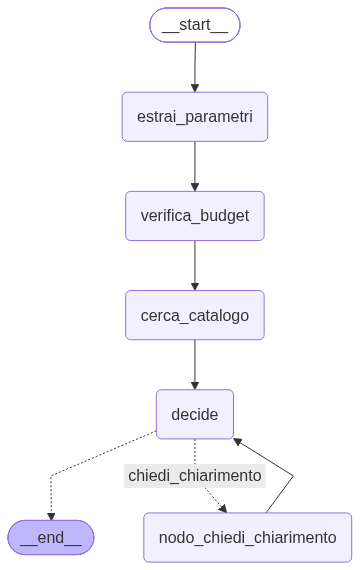

In [46]:
# Visualizza il grafo (richiede graphviz o pillow)
try:
    from IPython.display import Image, display
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    print(graph.get_graph().draw_mermaid())

## 5. Esecuzione del Grafo

In [47]:
def esegui(richiesta: str, employee_id: str = None, prodotto: str = None) -> dict:
    stato = {"richiesta": richiesta, "retry_count": 0, "errori": []}
    if employee_id: 
        stato["employee_id"]   = employee_id
    if prodotto:    
        stato["prodotto_query"] = prodotto
    print(f"\n{'═'*55}")
    print(f"  🚀 {richiesta[:200]}..." if len(richiesta)>200 else f"  🚀 {richiesta}")
    print(f"{'═'*55}")
    risultato = graph.invoke(stato)
    print(f"\n  Esito: {risultato.get('esito')}")
    print(f"  Risposta: {risultato.get('risposta_finale')}")
    return risultato

In [48]:
# Scenario 1: approvazione automatica
s1 = esegui(
    "Ciao, sono Mario Rossi (E4521). Voglio acquistare il ThinkPad P16s."
)


═══════════════════════════════════════════════════════
  🚀 Ciao, sono Mario Rossi (E4521). Voglio acquistare il ThinkPad P16s.
═══════════════════════════════════════════════════════
  🔍 [Nodo: estrai_parametri]
     → employee_id=E4521, prodotto=ThinkPad P16s
  💰 [Nodo: verifica_budget]
     → Mario Rossi | Senior Developer | budget: 1800€
  📦 [Nodo: cerca_catalogo]
     → 1 prodotti trovati, prezzi: [1650]€
  🧠 [Nodo: decide]
     → Esito: APPROVATO
  🔀 [Router] esito=APPROVATO, retry=0

  Esito: APPROVATO
  Risposta: Il richiedente Mario Rossi ha ottenuto l'approvazione per l'acquisto del ThinkPad P16s.


In [49]:
# Scenario 2: escalation — monitor costoso fuori budget
s2 = esegui(
    "Salve, sono Giulia Verdi (E1082). Ho bisogno del monitor 4K Dell UltraSharp.",
    employee_id="E1082", prodotto="monitor"
)


═══════════════════════════════════════════════════════
  🚀 Salve, sono Giulia Verdi (E1082). Ho bisogno del monitor 4K Dell UltraSharp.
═══════════════════════════════════════════════════════
  🔍 [Nodo: estrai_parametri]
     → employee_id=E1082, prodotto=monitor
  💰 [Nodo: verifica_budget]
     → Giulia Verdi | Content Specialist | budget: 450€
  📦 [Nodo: cerca_catalogo]
     → 1 prodotti trovati, prezzi: [520]€
  🧠 [Nodo: decide]
     → Esito: ESCALATION
  🔀 [Router] esito=ESCALATION, retry=0

  Esito: ESCALATION
  Risposta: La richiesta di acquisto del monitor è stata escalationata al manager per autorizzazione.


In [50]:
# Scenario 3: failure path — dipendente inesistente
s3 = esegui(
    "Ciao, sono Giovanni Bianchi (E9999). Voglio un laptop."
)


═══════════════════════════════════════════════════════
  🚀 Ciao, sono Giovanni Bianchi (E9999). Voglio un laptop.
═══════════════════════════════════════════════════════
  🔍 [Nodo: estrai_parametri]
     → employee_id=E9999, prodotto=laptop
  💰 [Nodo: verifica_budget]
  📦 [Nodo: cerca_catalogo]
     → 2 prodotti trovati, prezzi: [1650, 950]€
  🧠 [Nodo: decide]
  🔀 [Router] esito=RIFIUTO, retry=0

  Esito: RIFIUTO
  Risposta: ❌ 'E9999' non trovato.


## 6. Streaming — Stato dopo Ogni Nodo

Con `.stream()` osserviamo il dizionario parziale restituito da ciascun nodo
man mano che il grafo avanza.

In [51]:
print("Streaming step-by-step:\n")
for step in graph.stream(
    {"richiesta": "Mario Rossi E4521 ThinkPad",
     #"employee_id": "E4521", "prodotto_query": "ThinkPad",
     "retry_count": 0, "errori": []}
):
    nodo  = list(step.keys())[0]
    delta = list(step.values())[0]
    print(f"  [{nodo}]")
    for k, v in delta.items():
        v_str = json.dumps(v, ensure_ascii=False) if isinstance(v, (dict,list)) else str(v)
        print(f"    {k}: {v_str[:80]}{'...' if len(v_str)>80 else ''}")

Streaming step-by-step:

  🔍 [Nodo: estrai_parametri]
     → employee_id=Mario Rossi, prodotto=E4521 ThinkPad
  [estrai_parametri]
    employee_id: Mario Rossi
    prodotto_query: E4521 ThinkPad
  💰 [Nodo: verifica_budget]
  [verifica_budget]
    budget_data: {"status": "NOT_FOUND", "message": "'Mario Rossi' non trovato."}
    errori: ["dipendente Mario Rossi non trovato"]
  📦 [Nodo: cerca_catalogo]
     → 1 prodotti trovati, prezzi: [1650]€
  [cerca_catalogo]
    catalog_data: {"status": "OK", "risultati": {"LAP-DEV-01": {"name": "ThinkPad P16s Gen 2 / Mac...
  🧠 [Nodo: decide]
  🔀 [Router] esito=RIFIUTO, retry=0
  [decide]
    esito: RIFIUTO
    motivazione: 'Mario Rossi' non trovato.
    risposta_finale: ❌ 'Mario Rossi' non trovato.


---
## Pattern Agent: Classe Riutilizzabile

Il grafo è incapsulato in una classe `Agent`:
```python
class Agent:
    def __init__(self, model, tools, system=""): ...
    def call_openai(self, state): ...
    def exists_action(self, state): ...
    def take_action(self, state): ...
```
Questo pattern ha un vantaggio chiave: il grafo ReAct (LLM → tool → LLM → …)
diventa **riutilizzabile e configurabile** — basta passare modello, tool e system prompt diversi.

Ora applichiamo lo stesso identico pattern al nostro caso d'uso aziendale:
- `ChatOllama`
- I tool del dominio: `verifica_budget_tool`, `cerca_catalogo_tool`, `consulta_policy_tool`
- Lo stato `AgentState` con `messages: Annotated[list[AnyMessage], operator.add]`

> **Differenza rispetto alla sezione precedente**: lì lo stato era un `TypedDict` strutturato
> con campi espliciti (`budget_data`, `catalog_data`, ecc.) e il routing era scritto a mano.
> Qui lo stato è solo una lista di messaggi: è il LLM che decide quale tool chiamare e quando.
> I due approcci sono complementari — più controllo vs più autonomia.

### Tool LangChain per il dominio aziendale

I tool devono essere decorati con `@tool` e avere docstring descrittive:
è da lì che il LLM impara cosa fa ogni tool e quando invocarlo.

In [52]:
from langchain_core.messages import AnyMessage, SystemMessage, ToolMessage
from langchain_core.tools import tool

# ── Tool 1: verifica budget ────────────────────────────────────────────────────
@tool
def verifica_budget_tool(employee_id: str) -> str:
    """Verifica il budget residuo di un dipendente dato il suo badge ID.

    Args:
        employee_id: Badge ID del dipendente (es. 'E4521')
    """
    employees = json.loads((DATA_DIR / 'employees.json').read_text())
    emp = employees.get(employee_id)
    if not emp:
        return f"Dipendente '{employee_id}' non trovato nel sistema."
    return (
        f"Dipendente: {emp['name']} | Ruolo: {emp['role']} | "
        f"Dipartimento: {emp['department']}\n"
        f"Budget residuo: {emp['budget_residuo']} EUR\n"
        f"Progetto attivo: {emp.get('active_project', 'N/A')}\n"
        f"Manager: {emp['manager_email']}"
    )


# ── Tool 2: cerca nel catalogo ─────────────────────────────────────────────────
@tool
def cerca_catalogo_tool(query: str) -> str:
    """Cerca prodotti nel catalogo aziendale per nome o categoria.

    Args:
        query: Termine di ricerca (es. 'laptop', 'monitor', 'ThinkPad')
    """
    products = json.loads((DATA_DIR / 'products.json').read_text())
    q = query.lower()
    stopwords = {'per', 'del', 'con', 'un', 'il', 'la', 'sono', 'ciao', 'vorrei'}
    keywords = [k for k in q.split() if len(k) >= 2 and k not in stopwords]
    results = {
        pid: p for pid, p in products.items()
        if any(kw in f"{p['name']} {p['category']}".lower() for kw in keywords)
    }
    if not results:
        return f"Nessun prodotto trovato per '{query}'."
    righe = [f"Trovati {len(results)} prodotto/i per '{query}':"]
    for pid, p in results.items():
        righe.append(f"  • [{pid}] {p['name']} — {p['price_eur']} EUR ({p['category']})")
    return '\n'.join(righe)


# ── Tool 3: consulta policy ────────────────────────────────────────────────────
@tool
def consulta_policy_tool(categoria: str) -> str:
    """Consulta le policy aziendali per una categoria di hardware e ruolo.

    Args:
        categoria: Categoria di prodotto (es. 'laptop', 'monitor', 'accessory')
    """
    policy = (DATA_DIR / 'policy_hardware.md').read_text()
    cat = categoria.lower()
    lines, sezione, in_sec = policy.split('\n'), [], False
    for line in lines:
        if cat in line.lower() and line.startswith('##'):
            in_sec = True
        elif line.startswith('##') and in_sec:
            break
        if in_sec:
            sezione.append(line)
    return '\n'.join(sezione) if sezione else policy


tools_aziendali = [verifica_budget_tool, cerca_catalogo_tool, consulta_policy_tool]
print('Tool disponibili:', [t.name for t in tools_aziendali])

Tool disponibili: ['verifica_budget_tool', 'cerca_catalogo_tool', 'consulta_policy_tool']


### La classe `Agent`

> **Come funziona il grafo interno**: `llm` chiama il modello. Se la risposta contiene
> `tool_calls`, l'arco condizionale va a `action` che esegue i tool. Il risultato viene
> aggiunto ai messaggi e si torna a `llm`. Il ciclo termina quando il modello
> non richiede più nessun tool (`exists_action` restituisce `False`).

In [53]:
class Agent:
    """Agente ReAct generico"""

    def __init__(self, model, tools, system=''):
        self.system = system

        # Stato: solo una lista di messaggi (come Lesson 2)
        class AgentState(TypedDict):
            messages: Annotated[list[AnyMessage], operator.add]

        self.AgentState = AgentState

        # Costruisci il grafo interno
        graph = StateGraph(AgentState)
        graph.add_node('llm',    self.call_llm)
        graph.add_node('action', self.take_action)
        graph.add_conditional_edges(
            'llm',
            self.exists_action,
            {True: 'action', False: END}
        )
        graph.add_edge('action', 'llm')
        graph.set_entry_point('llm')
        self.graph = graph.compile()

        # Registry tool e modello con tool binding
        self.tools = {t.name: t for t in tools}
        self.model = model.bind_tools(tools)

    def exists_action(self, state):
        """Controlla se il LLM ha richiesto l'esecuzione di almeno un tool."""
        return len(state['messages'][-1].tool_calls) > 0

    def call_llm(self, state):
        """Nodo LLM: invoca il modello con i messaggi correnti."""
        messages = state['messages']
        if self.system:
            messages = [SystemMessage(content=self.system)] + messages
        message = self.model.invoke(messages)
        return {'messages': [message]}

    def take_action(self, state):
        """Nodo action: esegue tutti i tool richiesti e raccoglie i risultati."""
        tool_calls = state['messages'][-1].tool_calls
        results = []
        for t in tool_calls:
            print(f'  🔧 Chiamata tool: {t["name"]}({t["args"]})')
            if t['name'] not in self.tools:
                # Hallucination del LLM: nome tool inesistente — istruiamo a riprovare
                print('     ⚠️  Tool non trovato — istruzione a riprovare')
                result = f"Tool '{t['name']}' non esiste. Tool disponibili: {list(self.tools.keys())}"
            else:
                result = self.tools[t['name']].invoke(t['args'])
            results.append(ToolMessage(
                tool_call_id=t['id'],
                name=t['name'],
                content=str(result)
            ))
        print('  ↩️  Risultati inviati al modello')
        return {'messages': results}


print('✅ Classe Agent definita')

✅ Classe Agent definita


### Istanziazione

Passiamo modello, lista di tool e system prompt.
Il system prompt descrive il ruolo dell'agente e le regole che deve seguire.

In [54]:
system_prompt = """Sei l'Assistente Acquisti Hardware aziendale.
Il tuo compito è valutare le richieste di acquisto hardware dei dipendenti.

Usa i tool disponibili in questo ordine:
1. `verifica_budget_tool` — recupera budget residuo, ruolo e progetto attivo del dipendente
2. `cerca_catalogo_tool` — cerca il prodotto richiesto nel catalogo aziendale
3. `consulta_policy_tool` — consulta le policy per la categoria del prodotto trovato

Dopo aver raccolto tutti i dati, applica queste REGOLE DI DECISIONE nell'ordine indicato:

REGOLA 1 — RIFIUTO immediato se:
  - Il dipendente NON esiste nel sistema
  - Il prodotto NON è presente nel catalogo aziendale

REGOLA 2 — ESCALATION (richiede approvazione manager) se UNA di queste condizioni è vera:
  - CONDIZIONE A: il prodotto è della categoria 'monitor' o 'accessory'
    E il suo prezzo è SUPERIORE a 300 EUR
  - CONDIZIONE B: il prodotto è della categoria 'laptop'
    E il suo prezzo è SUPERIORE al budget residuo del dipendente

REGOLA 3 — APPROVATO se:
  - Nessuna condizione di RIFIUTO o ESCALATION è soddisfatta, E
  - Il prezzo del laptop è MINORE O UGUALE al budget residuo, E
  - Il dipartimento del dipendente è tra i target_roles del prodotto

ESEMPI NUMERICI (applicali come riferimento):
  Scenario A — Mario Rossi, E4521, Engineering, budget 1800 EUR, ThinkPad laptop 1650 EUR:
    1650 <= 1800 → budget OK | categoria laptop → soglia 300 EUR NON si applica
    → APPROVATO

  Scenario B — Giulia Verdi, E1082, Marketing, budget 450 EUR, monitor 4K 520 EUR:
    categoria monitor E prezzo 520 EUR > 300 EUR → CONDIZIONE A vera
    → ESCALATION (contatta il manager)

  Scenario C — dipendente E9999 non trovato → RIFIUTO

Rispondi sempre in italiano con la decisione in maiuscolo (APPROVATO / ESCALATION / RIFIUTO)
e la motivazione numerica."""

abot = Agent(
    model=ChatOllama(model='llama3.2', temperature=0),
    tools=tools_aziendali,
    system=system_prompt
)
print('✅ Agente istanziato con', list(abot.tools.keys()))


✅ Agente istanziato con ['verifica_budget_tool', 'cerca_catalogo_tool', 'consulta_policy_tool']


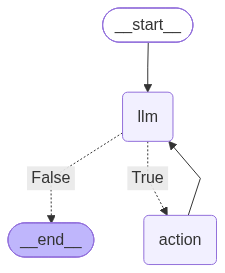

In [55]:
# Grafo interno dell'Agent
try:
    from IPython.display import Image, display
    display(Image(abot.graph.get_graph().draw_mermaid_png()))
except Exception:
    print(abot.graph.get_graph().draw_mermaid())

### Esecuzione

`abot.graph.invoke({"messages": [HumanMessage(...)]})`.
Lo stato è solo messaggi — il LLM decide in autonomia quali tool usare.

In [56]:
# Scenario 1 — Approvazione automatica (Mario Rossi, ThinkPad)
print('═' * 55)
print('Scenario 1: Mario Rossi — ThinkPad P16s')
print('═' * 55)
messages = [HumanMessage(content=(
    'Ciao, sono Mario Rossi (badge E4521). '
    'Vorrei acquistare un ThinkPad P16s per Project Delta. '
    'È possibile procedere?'
))]
result = abot.graph.invoke({'messages': messages})
print('\n🤖 Risposta finale:')
print(result['messages'][-1].content)

═══════════════════════════════════════════════════════
Scenario 1: Mario Rossi — ThinkPad P16s
═══════════════════════════════════════════════════════
  🔧 Chiamata tool: verifica_budget_tool({'employee_id': 'E4521'})
  🔧 Chiamata tool: cerca_catalogo_tool({'query': 'ThinkPad P16s'})
  🔧 Chiamata tool: consulta_policy_tool({'categoria': 'laptop'})
  ↩️  Risultati inviati al modello

🤖 Risposta finale:
**DECISIONE**

Dopo aver verificato i dati e confrontato le specifiche con la policy aziendale, si conclude che la richiesta di acquisto del ThinkPad P16s per Project Delta di Mario Rossi (badge E4521) è **APPROVATA**.

La spesa del laptop è di 1650 EUR, che è minore o uguale al budget residuo di 1800 EUR. Il dipartimento di Mario Rossi (Engineering) è tra i target_roles del prodotto, quindi la richiesta è stata approvata automaticamente.

**MOTIVAZIONE**

La richiesta è stata approvata perché il costo del laptop (1650 EUR) è minore o uguale al budget residuo del dipendente (1800 EUR). Il

In [57]:
# Scenario 2 — Escalation (Giulia Verdi, monitor 4K)
print('═' * 55)
print('Scenario 2: Giulia Verdi — Monitor 4K Dell UltraSharp')
print('═' * 55)
messages = [HumanMessage(content=(
    'Salve, sono Giulia Verdi (E1082), Marketing. '
    'Ho bisogno del monitor 4K Dell UltraSharp per lavoro grafico. '
    'Posso acquistarlo?'
))]
result = abot.graph.invoke({'messages': messages})
print('\n🤖 Risposta finale:')
print(result['messages'][-1].content)

═══════════════════════════════════════════════════════
Scenario 2: Giulia Verdi — Monitor 4K Dell UltraSharp
═══════════════════════════════════════════════════════
  🔧 Chiamata tool: verifica_budget_tool({'employee_id': 'E1082'})
  🔧 Chiamata tool: cerca_catalogo_tool({'query': 'monitor 4K'})
  🔧 Chiamata tool: consulta_policy_tool({'categoria': 'monitor'})
  ↩️  Risultati inviati al modello

🤖 Risposta finale:
RIFIUTO

Motivazione: Il dipendente Giulia Verdi (E1082) non esiste nel sistema oppure il prodotto Dell UltraSharp 27 4K (U2723QE) non è presente nel catalogo aziendale.


In [58]:
# Scenario 3 — Dipendente non trovato
print('═' * 55)
print('Scenario 3: Dipendente inesistente')
print('═' * 55)
messages = [HumanMessage(content=(
    'Ciao, sono Giovanni Bianchi (E9999). Voglio un laptop.'
))]
result = abot.graph.invoke({'messages': messages})
print('\n🤖 Risposta finale:')
print(result['messages'][-1].content)

═══════════════════════════════════════════════════════
Scenario 3: Dipendente inesistente
═══════════════════════════════════════════════════════
  🔧 Chiamata tool: verifica_budget_tool({'employee_id': 'E9999'})
  🔧 Chiamata tool: cerca_catalogo_tool({'query': 'laptop'})
  🔧 Chiamata tool: consulta_policy_tool({'categoria': 'laptop'})
  ↩️  Risultati inviati al modello

🤖 Risposta finale:
RIFIUTO

Motivazione: Dipendente 'E9999' non trovato nel sistema.


### Ispezione della cronologia messaggi

Possiamo ispezionare l'intera lista di messaggi per vedere il ciclo LLM → tool → LLM in dettaglio.

In [ ]:
messages = [HumanMessage(content=(
    'Salve, sono Giulia Verdi (E1082), Marketing. '
    'Ho bisogno del monitor 4K Dell UltraSharp per lavoro grafico. '
    'Posso acquistarlo?'
))]
result = abot.graph.invoke({'messages': messages})

print('Cronologia messaggi:')
for msg in result['messages']:
    tipo = type(msg).__name__
    if hasattr(msg, 'tool_calls') and msg.tool_calls:
        calls = [f"{tc['name']}" for tc in msg.tool_calls]
        print(f'  [{tipo}] tool_calls={calls}')
    elif hasattr(msg, 'name') and msg.name:  # ToolMessage
        preview = str(msg.content)[:200].replace('\n', ' ')
        print(f'  [{tipo}:{msg.name}] {preview}...')
    else:
        preview = str(msg.content)[:200].replace('\n', ' ')
        print(f'  [{tipo}] {preview}...')

  🔧 Chiamata tool: verifica_budget_tool({'employee_id': 'E1082'})
  🔧 Chiamata tool: cerca_catalogo_tool({'query': 'monitor 4K'})
  🔧 Chiamata tool: consulta_policy_tool({'categoria': 'monitor'})
  ↩️  Risultati inviati al modello
Cronologia messaggi:
  [HumanMessage] Salve, sono Giulia Verdi (E1082), Marketing. Ho bisogno del monitor 4K Dell UltraSharp per lavoro grafico. Posso acquistarlo?...
  [AIMessage] tool_calls=['verifica_budget_tool', 'cerca_catalogo_tool', 'consulta_policy_tool']
  [ToolMessage:verifica_budget_tool] Dipendente: Giulia Verdi | Ruolo: Content Specialist | Dipartimento: Marketing Budget residuo: 450 EUR Progetto attivo: Brand Campaign Q2 Manager: luca.neri@azienda.it...
  [ToolMessage:cerca_catalogo_tool] Trovati 1 prodotto/i per 'monitor 4K':   • [MON-4K-01] Dell UltraSharp 27 4K (U2723QE) — 520 EUR (monitor)...
  [ToolMessage:consulta_policy_tool] # POLICY AZIENDALE ACQUISTI HARDWARE E DOTAZIONI IT  ## 1. Ambito e Obiettivo La presente policy disciplina le ric

: 

### Confronto: classe `Agent` vs grafo esplicito

| | Classe `Agent` (questo paragrafo) | Grafo esplicito (paragrafi 1–5) |
|---|---|---|
| **Stato** | Solo messaggi | `TypedDict` con campi strutturati |
| **Routing** | Il LLM decide quali tool usare | Funzioni Python esplicite |
| **Trasparenza** | Difficile da debuggare | `.stream()` per nodo |
| **Flessibilità** | Alta (il LLM si adatta) | Bassa (flusso fisso) |
| **Prevedibilità** | Media | Alta |
| **Quando usarlo** | Problemi aperti, tool generici | Flussi di business ben definiti |

**Regola pratica**: usa la classe `Agent` per esplorazione e prototipazione rapida;
usa il grafo esplicito quando hai un processo aziendale definito con esiti precisi.

## 7. Esercizi

### Esercizio A — Nodo di Validazione
Aggiungi un nodo `valida_input` tra `START` e `estrai_parametri` che rifiuta
richieste vuote o troppo corte (< 10 caratteri) impostando `esito = "ERRORE"`.

In [60]:
def valida_input(state: StatoRichiesta) -> dict:
    """TODO: valida che la richiesta non sia vuota o troppo corta."""
    richiesta = state.get("richiesta", "")
    # TODO: implementa
    return {}

def router_dopo_validazione(state: StatoRichiesta) -> str:
    """TODO: se esito == ERRORE → END, altrimenti → estrai_parametri."""
    # TODO
    return "estrai_parametri"

print("💡 Implementa le funzioni, poi ricostruisci il grafo inserendo valida_input come primo nodo.")

💡 Implementa le funzioni, poi ricostruisci il grafo inserendo valida_input come primo nodo.


### Esercizio B — Osserva il Ciclo di Chiarimento

Modifica `chiedi_chiarimento` per restituire sempre una risposta vaga
(es. `"Non lo so"`) e osserva come il grafo cicla fino al max retry.

---
### Riepilogo
- `TypedDict` → schema dello stato condiviso tra nodi
- Ogni nodo restituisce solo i **campi aggiornati** (dict parziale)
- `add_conditional_edges` → routing dinamico basato sullo stato
- Un arco che torna indietro crea un **ciclo**; `retry_count` lo controlla
- `.stream()` → introspection step-by-step dello stato